# vLLM vs Naive HF Benchmark

In [ ]:
!pip install -q vllm==0.6.6.post1 "transformers<5.0.0" accelerate pandas matplotlib numpy
!pip uninstall -y torchaudio torchvision gradio

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 3.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.0/61.0 kB 6.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 201.1/201.1 MB 7.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 87.5/87.5 kB 9.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 71.6/71.6 kB 7.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 111.0/111.0 kB 12.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 87.6/87.6 kB 9.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 906.4/906.4 MB 810.4 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.2/7.2 MB 119.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 58.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 5.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 81.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6

In [ ]:
%%writefile config.py
import os
os.makedirs('results', exist_ok=True)
os.makedirs('plots', exist_ok=True)

MODEL_NAME = "Qwen/Qwen2.5-3B-Instruct"
BATCH_SIZES = [1, 4, 8, 16, 32]
LENGTH_BUCKETS = ["short", "medium", "long"]
MAX_NEW_TOKENS = 256
SEED = 42

SHORT_PROMPTS = [
    "Explain the difference between supervised and unsupervised learning in two sentences.",
    "What is the time complexity of binary search?",
    "Summarize the plot of a mystery novel in one paragraph.",
    "Write a haiku about distributed systems.",
    "What are the main causes of the 2008 financial crisis?",
]
MEDIUM_PROMPTS = [
    "You are reviewing a pull request for a production RAG pipeline. The PR adds a new chunking strategy that splits documents by semantic similarity rather than fixed token windows. Write a code review comment identifying two potential risks with this approach and one suggestion for mitigating each risk.",
    "A user reports that their computer vision model, deployed on an NVIDIA Jetson Orin, is running at 15 FPS instead of the expected 50 FPS after a recent TensorRT engine rebuild. List five likely causes, ordered by probability, and a diagnostic step for each.",
    "Explain how PagedAttention reduces GPU memory fragmentation compared to naive KV-cache allocation in transformer inference serving. Include a brief analogy to OS virtual memory paging.",
]
LONG_PROMPTS = [
    "You are architecting a multi-agent research system. The system has 11 specialized agents: a query planner, five domain-specific researchers, a fact-checker, a citation verifier, a synthesis agent, an LLM-as-Judge evaluator, and a final formatter. Agents communicate through a shared state graph implemented in LangGraph. Design a memory architecture that prevents agents from reinforcing each other's factual errors while still allowing them to build on each other's partial findings. Discuss: (1) what should be agent-local vs. shared state, (2) how you would detect and interrupt an error-reinforcement loop before it propagates to the final synthesis, and (3) how the LLM-as-Judge evaluator's feedback should be routed back into the pipeline -- as a hard rejection, a soft re-ranking signal, or a targeted re-query to specific agents. Be specific about tradeoffs.",
    "Write a detailed incident postmortem for the following scenario: A production RAG system serving 2,500+ regulatory documents began returning degraded retrieval quality over a 6-hour window. P99 latency increased from 800ms to 4.2s, and a spot-check of 20 queries showed 6 with clearly irrelevant retrieved chunks. The vector database is pgvector on RDS, embeddings are generated via a hosted API, and the deployment uses a blue-green rollout strategy. Walk through a plausible root cause investigation, identify the most likely root cause, and propose both an immediate mitigation and a longer-term structural fix to prevent recurrence.",
]
ALL_PROMPTS = {"short": SHORT_PROMPTS, "medium": MEDIUM_PROMPTS, "long": LONG_PROMPTS}

def get_prompt_batch(size, length_bucket="medium"):
    pool = ALL_PROMPTS[length_bucket]
    return [pool[i % len(pool)] for i in range(size)]

In [ ]:
%%writefile run_vllm.py
import time, json, numpy as np, torch
from vllm import LLM, SamplingParams
from dataclasses import dataclass, asdict
from config import MODEL_NAME, BATCH_SIZES, LENGTH_BUCKETS, MAX_NEW_TOKENS, SEED, get_prompt_batch

@dataclass
class RunResult:
    batch_size: int
    length_bucket: str
    total_prompts: int
    wall_clock_sec: float
    total_tokens_generated: int
    throughput_tokens_per_sec: float
    ttfb_p50_ms: float
    ttfb_p90_ms: float
    ttfb_p99_ms: float
    per_token_latency_p50_ms: float
    peak_gpu_mem_gb: float

print(f"Loading {MODEL_NAME} with vLLM...")
llm = LLM(model=MODEL_NAME, gpu_memory_utilization=0.85, dtype="float16", seed=SEED)
vllm_results = []

for length_bucket in LENGTH_BUCKETS:
    for batch_size in BATCH_SIZES:
        prompts = get_prompt_batch(batch_size, length_bucket)
        sampling_params = SamplingParams(temperature=0.7, max_tokens=MAX_NEW_TOKENS, seed=SEED)

        torch.cuda.reset_peak_memory_stats()
        torch.cuda.synchronize()
        start = time.perf_counter()
        outputs = llm.generate(prompts, sampling_params)
        torch.cuda.synchronize()
        elapsed = time.perf_counter() - start

        total_tokens = sum(len(o.outputs[0].token_ids) for o in outputs)
        peak_mem_gb = torch.cuda.max_memory_allocated() / (1024**3)

        ttfbs_ms = []
        for o in outputs:
            m = getattr(o, "metrics", None)
            if m and getattr(m, "first_token_time", None) and getattr(m, "arrival_time", None):
                ttfbs_ms.append((m.first_token_time - m.arrival_time) * 1000)
        if not ttfbs_ms:
            ttfbs_ms = [0.0]

        per_token_ms = (elapsed * 1000) / max(total_tokens, 1) * batch_size

        result = RunResult(
            batch_size=batch_size, length_bucket=length_bucket, total_prompts=len(prompts),
            wall_clock_sec=round(elapsed, 4), total_tokens_generated=total_tokens,
            throughput_tokens_per_sec=round(total_tokens / elapsed, 2),
            ttfb_p50_ms=round(float(np.percentile(ttfbs_ms, 50)), 2),
            ttfb_p90_ms=round(float(np.percentile(ttfbs_ms, 90)), 2),
            ttfb_p99_ms=round(float(np.percentile(ttfbs_ms, 99)), 2),
            per_token_latency_p50_ms=round(per_token_ms, 3),
            peak_gpu_mem_gb=round(peak_mem_gb, 2),
        )
        vllm_results.append(result)
        print(f"[vLLM] batch={batch_size:2d} bucket={length_bucket:6s} throughput={result.throughput_tokens_per_sec:>8.1f} tok/s peak_mem={result.peak_gpu_mem_gb:.2f}GB")

with open('results/vllm_results.json', 'w') as f:
    json.dump({"engine": "vllm", "model": MODEL_NAME, "max_new_tokens": MAX_NEW_TOKENS, "seed": SEED,
               "runs": [asdict(r) for r in vllm_results]}, f, indent=2)
print("\nSaved results/vllm_results.json")


In [ ]:
!python run_vllm.py

2026-07-18 15:18:42.769219: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
Loading Qwen/Qwen2.5-3B-Instruct with vLLM...
config.json: 100% 661/661 [00:00<00:00, 4.54MB/s]
`torch_dtype` is deprecated! Use `dtype` instead!
WARNING 07-18 15:19:00 config.py:2276] Casting torch.bfloat16 to torch.float16.
INFO 07-18 15:19:18 config.py:510] This model supports multiple tasks: {'score', 'generate', 'classify', 'embed', 'reward'}. Defaulting to 'generate'.
INFO 07-18 15:19:18 llm_engine.py:234] Initializing an LLM engine (v0.6.6.post1) with config: model='Qwen/Qwen2.5-3B-Instruct', speculative_config=None, tokenizer='Qwen/Qwen2.5-3B-Instruct', skip_tokenizer_init=False, tokenizer_mode=auto, revision=None, override_neuron_config=None, tokenizer_revision=N

In [ ]:
%%writefile run_baseline.py
import time, json, numpy as np, torch
from transformers import AutoModelForCausalLM, AutoTokenizer
from dataclasses import dataclass, asdict
from config import MODEL_NAME, BATCH_SIZES, LENGTH_BUCKETS, MAX_NEW_TOKENS, SEED, get_prompt_batch

@dataclass
class BaselineRunResult:
    batch_size: int
    length_bucket: str
    total_prompts: int
    wall_clock_sec: float
    total_tokens_generated: int
    throughput_tokens_per_sec: float
    ttfb_p50_ms: float
    peak_gpu_mem_gb: float

print(f"Loading {MODEL_NAME} with naive HF generate()...")
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token
tokenizer.padding_side = "left"

model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, torch_dtype=torch.float16, device_map="auto")
model.eval()
baseline_results = []

for length_bucket in LENGTH_BUCKETS:
    for batch_size in BATCH_SIZES:
        prompts = get_prompt_batch(batch_size, length_bucket)
        inputs = tokenizer(prompts, return_tensors="pt", padding=True, truncation=True).to("cuda")

        torch.cuda.reset_peak_memory_stats()
        torch.manual_seed(SEED)
        torch.cuda.manual_seed_all(SEED)
        torch.cuda.synchronize()
        start = time.perf_counter()
        with torch.no_grad():
            output_ids = model.generate(
                **inputs, max_new_tokens=MAX_NEW_TOKENS, do_sample=True,
                temperature=0.7, pad_token_id=tokenizer.eos_token_id,
            )
        torch.cuda.synchronize()
        elapsed = time.perf_counter() - start

        new_tokens = output_ids[:, inputs["input_ids"].shape[1]:]
        total_tokens = int((new_tokens != tokenizer.pad_token_id).sum().item())
        peak_mem_gb = torch.cuda.max_memory_allocated() / (1024**3)
        approx_ttfb_ms = (elapsed / MAX_NEW_TOKENS) * 1000

        result = BaselineRunResult(
            batch_size=batch_size, length_bucket=length_bucket, total_prompts=len(prompts),
            wall_clock_sec=round(elapsed, 4), total_tokens_generated=total_tokens,
            throughput_tokens_per_sec=round(total_tokens / elapsed, 2),
            ttfb_p50_ms=round(approx_ttfb_ms, 2), peak_gpu_mem_gb=round(peak_mem_gb, 2),
        )
        baseline_results.append(result)
        print(f"[Baseline] batch={batch_size:2d} bucket={length_bucket:6s} throughput={result.throughput_tokens_per_sec:>8.1f} tok/s peak_mem={result.peak_gpu_mem_gb:.2f}GB")

with open('results/baseline_results.json', 'w') as f:
    json.dump({"engine": "huggingface_naive", "model": MODEL_NAME, "max_new_tokens": MAX_NEW_TOKENS, "seed": SEED,
               "runs": [asdict(r) for r in baseline_results]}, f, indent=2)
print("\nSaved results/baseline_results.json")


In [ ]:
!python run_baseline.py

Loading Qwen/Qwen2.5-3B-Instruct with naive HF generate()...
`torch_dtype` is deprecated! Use `dtype` instead!
2026-07-18 15:25:14.688722: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
Loading checkpoint shards: 100% 2/2 [00:24<00:00, 12.21s/it]
[Baseline] batch= 1 bucket=short  throughput=    11.9 tok/s peak_mem=5.77GB
[Baseline] batch= 4 bucket=short  throughput=    70.5 tok/s peak_mem=5.83GB
[Baseline] batch= 8 bucket=short  throughput=   138.4 tok/s peak_mem=5.92GB
[Baseline] batch=16 bucket=short  throughput=   261.8 tok/s peak_mem=6.06GB
[Baseline] batch=32 bucket=short  throughput=   430.0 tok/s peak_mem=6.34GB
[Baseline] batch= 1 bucket=medium throughput=    17.6 tok/s peak_mem=5.78GB
[Baseline] batch= 4 bucket=medium throughput=    71.

In [ ]:
!pip install -qU numpy pandas matplotlib

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 4.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 7.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 98.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.9/10.9 MB 125.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.0/10.0 MB 120.2 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
vllm 0.6.6.post1 requires torchvision==0.20.1, which is not installed.
fastai 2.8.7 requires torchvision>=0.11, which is not installed.
vllm 0.6.6.post1 requires numpy<2.0.0, but you have numpy 2.5.1 which is incompatible.
mistral-common 1.11.6 requires numpy<2.4,>=1.25; python_version <= "3.12", but you have numpy 2.5.1 which is incompatible.
google-colab 1.0.0 requires pandas==2.2.2, but you have pandas 3.0.3 which is in

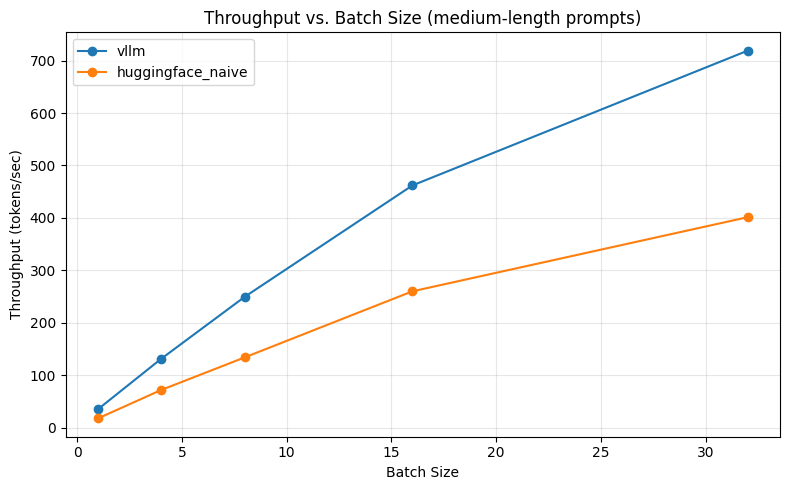

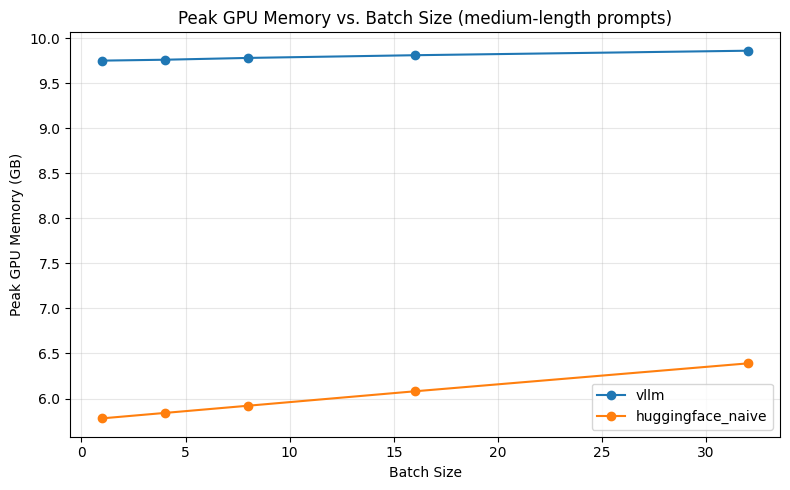


=== SHORT ===
batch= 1  vLLM=   31.9 tok/s  baseline=   11.9 tok/s  speedup=2.69x
batch= 4  vLLM=   50.5 tok/s  baseline=   70.5 tok/s  speedup=0.72x
batch= 8  vLLM=  139.4 tok/s  baseline=  138.4 tok/s  speedup=1.01x
batch=16  vLLM=  251.5 tok/s  baseline=  261.8 tok/s  speedup=0.96x
batch=32  vLLM=  466.3 tok/s  baseline=  430.0 tok/s  speedup=1.08x

=== MEDIUM ===
batch= 1  vLLM=   35.2 tok/s  baseline=   17.6 tok/s  speedup=2.00x
batch= 4  vLLM=  130.9 tok/s  baseline=   71.6 tok/s  speedup=1.83x
batch= 8  vLLM=  249.5 tok/s  baseline=  133.9 tok/s  speedup=1.86x
batch=16  vLLM=  461.8 tok/s  baseline=  259.9 tok/s  speedup=1.78x
batch=32  vLLM=  718.8 tok/s  baseline=  401.2 tok/s  speedup=1.79x

=== LONG ===
batch= 1  vLLM=   34.3 tok/s  baseline=   17.2 tok/s  speedup=1.99x
batch= 4  vLLM=  127.8 tok/s  baseline=   70.2 tok/s  speedup=1.82x
batch= 8  vLLM=  237.8 tok/s  baseline=  137.4 tok/s  speedup=1.73x
batch=16  vLLM=  423.8 tok/s  baseline=  236.1 tok/s  speedup=1.80x
bat

In [ ]:
import json
import pandas as pd
import matplotlib.pyplot as plt

def load_results(path):
    with open(path) as f:
        data = json.load(f)
    df = pd.DataFrame(data['runs'])
    df['engine'] = data['engine']
    df['model'] = data['model']
    return df

vllm_df = load_results('results/vllm_results.json')
baseline_df = load_results('results/baseline_results.json')
combined = pd.concat([vllm_df, baseline_df], ignore_index=True)

fig, ax = plt.subplots(figsize=(8,5))
for engine in combined['engine'].unique():
    subset = combined[(combined['engine']==engine) & (combined['length_bucket']=='medium')].sort_values('batch_size')
    ax.plot(subset['batch_size'], subset['throughput_tokens_per_sec'], marker='o', label=engine)
ax.set_xlabel('Batch Size'); ax.set_ylabel('Throughput (tokens/sec)')
ax.set_title('Throughput vs. Batch Size (medium-length prompts)')
ax.legend(); ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig('plots/throughput_vs_batch.png', dpi=150)
plt.show()

fig, ax = plt.subplots(figsize=(8,5))
for engine in combined['engine'].unique():
    subset = combined[(combined['engine']==engine) & (combined['length_bucket']=='medium')].sort_values('batch_size')
    ax.plot(subset['batch_size'], subset['peak_gpu_mem_gb'], marker='o', label=engine)
ax.set_xlabel('Batch Size'); ax.set_ylabel('Peak GPU Memory (GB)')
ax.set_title('Peak GPU Memory vs. Batch Size (medium-length prompts)')
ax.legend(); ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig('plots/memory_vs_batch.png', dpi=150)
plt.show()

for bucket in ['short','medium','long']:
    print(f"\n=== {bucket.upper()} ===")
    for batch in sorted(vllm_df['batch_size'].unique()):
        v = vllm_df[(vllm_df['batch_size']==batch)&(vllm_df['length_bucket']==bucket)]
        b = baseline_df[(baseline_df['batch_size']==batch)&(baseline_df['length_bucket']==bucket)]
        if v.empty or b.empty: continue
        v_tps, b_tps = v['throughput_tokens_per_sec'].iloc[0], b['throughput_tokens_per_sec'].iloc[0]
        print(f"batch={batch:2d}  vLLM={v_tps:>7.1f} tok/s  baseline={b_tps:>7.1f} tok/s  speedup={v_tps/b_tps:.2f}x")

In [ ]:
!zip -r vllm_benchmark_results.zip results/ plots/
from google.colab import files
files.download('vllm_benchmark_results.zip')